In [3]:
import gensim
import pandas as pd
import numpy as np
from keras import layers
from keras import models
import simpletransformers
from gensim.models import Word2Vec
from clean_text import clean_text
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from keras.preprocessing.text import Tokenizer
from sklearn.model_selection import train_test_split
from keras.preprocessing.sequence import pad_sequences
from simpletransformers.language_representation import RepresentationModel

In [4]:
train_df = pd.read_csv("train.csv")
copy_train_df = train_df.copy()
copy_train_df.drop(["id", "discourse_id", "discourse_start", "discourse_end", "discourse_type_num", "predictionstring"], axis=1, inplace=True)

In [3]:
discourse_text = []
discourse_type = []
for i,paragraph in enumerate(copy_train_df.discourse_text):
    types = []
    phrases = sent_tokenize(paragraph)
    types.append(copy_train_df.discourse_type[i])
    discourse_text.extend(phrases)
    discourse_type.extend(types*len(phrases))

In [4]:
copy_train_df = pd.DataFrame({"discourse_text":discourse_text, "discourse_type":discourse_type})

In [5]:
copy_train_df.head(2)

,discourse_text,discourse_type
0,Modern humans today are always on their phone....,Lead
1,They are some really bad consequences when stu...,Position


In [6]:
copy_train_df.discourse_text = copy_train_df.discourse_text.apply(clean_text)

In [7]:
copy_train_df.head()

,discourse_text,discourse_type
0,modern human today always phone always phone n...,Lead
1,really bad consequence stuff happens come phone,Position
2,certain area united state ban phone class room,Evidence
3,people phone know certain apps apps like faceb...,Evidence
4,driving one way get around people always phone...,Claim


In [8]:
corpus = copy_train_df.discourse_text.apply(lambda x: [word for word in word_tokenize(x)])

In [9]:
tk = Tokenizer()
tk.fit_on_texts(copy_train_df.discourse_text)

In [29]:
# Word2Vec Parameters 
dimension = 300
window = 8
# max_length = max([len(doc) for doc in corpus])
max_length = 100
vocab_size = len(list(tk.word_index.items()))

In [30]:
modele = Word2Vec(corpus, vector_size=dimension, window=window)

In [1]:
words = modele.wv

NameError: name 'modele' is not defined

In [9]:
modele = RepresentationModel(
    model_type="bert",
    model_name="bert-base-uncased",
    use_cuda=False
)

Downloading: 100%|██████████| 420M/420M [10:47<00:00, 680kB/s]   
Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForTextRepresentation: ['cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.decoder.weight', 'cls.seq_relationship.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.weight']
- This IS expected if you are initializing BertForTextRepresentation from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTextRepresentation from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Downloading: 100%|██████████| 226k/226k [

In [ ]:
word_vectors = modele.encode_sentences(list(copy_train_df.discourse_text),combine_strategy=None)

In [32]:
embedding = np.zeros((vocab_size+1, dimension))
for word,idx in tk.word_index.items():
    try:
        embedding[idx] =  words[word]
    except:
        pass

In [14]:
embedding[:2, :]

array([[0.        , 0.        ],
       [4.73623514, 3.78535485]])

In [52]:
X_train, X_test, y_train, y_test = train_test_split(copy_train_df.discourse_text, copy_train_df.discourse_type, test_size=0.2, random_state=123)

In [33]:
seqTrain = tk.texts_to_sequences(X_train)
padTrain = pad_sequences(seqTrain, maxlen=max_length, padding='post')

In [17]:
def attention_layer(inputs, neurons):
    x = layers.Permute((2,1))(inputs)
    x = layers.Dense(neurons, activation="softmax")(x)
    x = layers.Permute((2,1), name="attention")(x)
    x = layers.multiply([inputs, x])
    return x

In [34]:
x_in = layers.Input(shape=(max_length,))

x = layers.Embedding(input_dim=embedding.shape[0],  
                     output_dim=embedding.shape[1], 
                     weights=[embedding],
                     input_length=max_length, trainable=False)(x_in)

# x = attention_layer(x, neurons=max_length)
# x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2))(x)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2))(x)
x = layers.Dense(64, activation='relu')(x)
y_out = layers.Dense(7, activation='softmax')(x)

model = models.Model(x_in, y_out)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 100)]             0         
                                                                 
 embedding_3 (Embedding)     (None, 100, 300)          14820600  
                                                                 
 bidirectional_2 (Bidirectio  (None, 200)              320800    
 nal)                                                            
                                                                 
 dense_6 (Dense)             (None, 64)                12864     
                                                                 
 dense_7 (Dense)             (None, 7)                 455       
                                                                 
Total params: 15,154,719
Trainable params: 334,119
Non-trainable params: 14,820,600
_________________________________________

In [53]:
dic_y_mapping = {n:label for n,label in 
                 enumerate(np.unique(y_train))}
inverse_dic = {v:k for k,v in dic_y_mapping.items()}
y_train = np.array([inverse_dic[y] for y in y_train])

In [35]:
training = model.fit(x=padTrain, y=y_train, batch_size=256, 
                     epochs=10, shuffle=True, verbose=1, 
                     validation_split=0.3)

Epoch 1/10
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
725/725 [==============================] - ETA: 0s - loss: 1.2206 - accuracy: 0.5671WARNING:tensorflow:AutoGraph could not transform <function Model.make_test_function.<locals>.test_function at 0x0000017135634D38> and will run it as-is.
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`

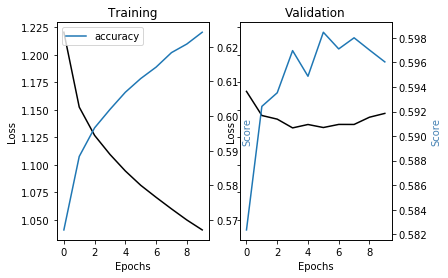

In [41]:
import matplotlib.pyplot as plt
metrics = [k for k in training.history.keys() if ("loss" not in k) and ("val" not in k)]
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
ax[0].set(title="Training")
ax11 = ax[0].twinx()
ax[0].plot(training.history['loss'], color='black')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss', color='black')
for metric in metrics:
    ax11.plot(training.history[metric], label=metric)
ax11.set_ylabel("Score", color='steelblue')
ax11.legend()
ax[1].set(title="Validation")
ax22 = ax[1].twinx()
ax[1].plot(training.history['val_loss'], color='black')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss', color='black')
for metric in metrics:
     ax22.plot(training.history['val_'+metric], label=metric)
ax22.set_ylabel("Score", color="steelblue")
plt.show()

In [42]:
seqTest = tk.texts_to_sequences(X_test)
padTest = pad_sequences(seqTest, maxlen=max_length, padding='post')

In [43]:
dic_y_mapping = {n:label for n,label in 
                 enumerate(np.unique(y_test))}
inverse_dic = {v:k for k,v in dic_y_mapping.items()}
y_test = np.array([inverse_dic[y] for y in y_test])

In [44]:
predicted_prob = model.predict(padTest)
predicted = [dic_y_mapping[np.argmax(pred)] for pred in 
             predicted_prob]

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


In [45]:
from sklearn.metrics import classification_report

In [47]:
predicted[:5]

['Evidence', 'Evidence', 'Evidence', 'Claim', 'Evidence']

In [57]:
print(classification_report(y_test, predicted))

                      precision    recall  f1-score   support

               Claim       0.51      0.30      0.37     10839
Concluding Statement       0.45      0.25      0.32      8472
        Counterclaim       0.53      0.23      0.32      1512
            Evidence       0.64      0.88      0.74     34792
                Lead       0.49      0.27      0.35      5648
            Position       0.52      0.44      0.48      3672
            Rebuttal       0.40      0.05      0.08      1310

            accuracy                           0.60     66245
           macro avg       0.51      0.35      0.38     66245
        weighted avg       0.57      0.60      0.56     66245



In [ ]:
list(words.key_to_index.items())[:5]

[('student', 0), ('would', 1), ('people', 2), ('school', 3), ('car', 4)]

In [ ]:
words.vectors.shape

(11347, 2)

In [ ]:
words["student"]

array([-4.3476696, -2.9557688], dtype=float32)

In [ ]:
words["nbr"]

array([ 4.7494483, -1.6019683], dtype=float32)

In [ ]:
words.similarity("percent", "student")

-0.6102177

In [ ]:
words.most_similar("article")

[('dioxide', 1.0000001192092896),
 ('january', 1.0),
 ('border', 1.0),
 ('hidden', 1.0),
 ('allready', 0.9999998211860657),
 ('luke', 0.9999997019767761),
 ('skated', 0.9999996423721313),
 ('visitor', 0.9999995827674866),
 ('racist', 0.9999995827674866),
 ('phelps', 0.9999995827674866)]

In [ ]:
mot = pd.DataFrame(words.vectors, columns=["V1", "V2"], index=list(words.index_to_key))

In [ ]:
mot.head()

,V1,V2
student,-4.347670,-2.955769
would,-1.684587,-2.031147
people,-1.127969,-1.983882
school,-2.896691,-2.339360
car,-1.802914,-2.389278


In [ ]:
import matplotlib.pyplot as plt

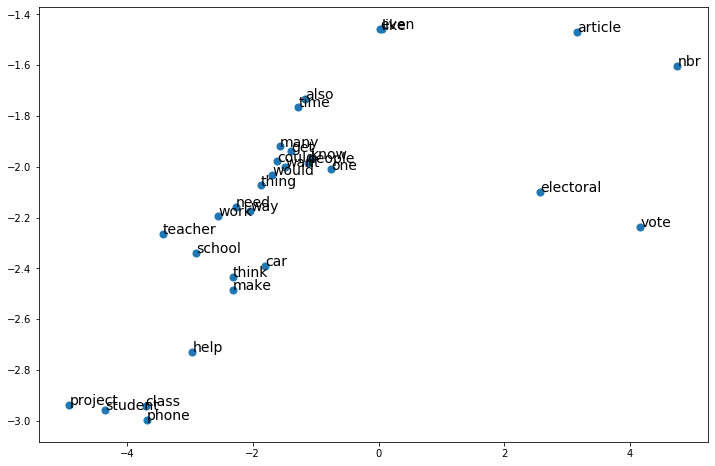

In [ ]:
plt.figure(figsize=(12,8))
plt.scatter(mot.iloc[:30, 0], mot.iloc[:30, 1], s=50)
for i in range(30):
    plt.annotate(mot.index[i], (mot.iloc[i,0], mot.iloc[i,1]), fontsize=14)

## Data comprehension

In [58]:
train_df.head()

,id,discourse_id,discourse_start,discourse_end,discourse_text,discourse_type,discourse_type_num,predictionstring
0,423A1CA112E2,1.622628e+12,8.0,229.0,Modern humans today are always on their phone....,Lead,Lead 1,1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 1...
1,423A1CA112E2,1.622628e+12,230.0,312.0,They are some really bad consequences when stu...,Position,Position 1,45 46 47 48 49 50 51 52 53 54 55 56 57 58 59
2,423A1CA112E2,1.622628e+12,313.0,401.0,Some certain areas in the United States ban ph...,Evidence,Evidence 1,60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75
3,423A1CA112E2,1.622628e+12,402.0,758.0,"When people have phones, they know about certa...",Evidence,Evidence 2,76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 9...
4,423A1CA112E2,1.622628e+12,759.0,886.0,Driving is one of the way how to get around. P...,Claim,Claim 1,139 140 141 142 143 144 145 146 147 148 149 15...


In [59]:
copy_train_df.head()

,discourse_text,discourse_type
0,modern human today always phone,Lead
1,always phone nbr hour day stop text back forwa...,Lead
2,even driving,Lead
3,really bad consequence stuff happens come phone,Position
4,certain area united state ban phone class room,Evidence


In [68]:
train_df.discourse_type.value_counts()

Claim                   50208
Evidence                45702
Position                15419
Concluding Statement    13505
Lead                     9305
Counterclaim             5817
Rebuttal                 4337
Name: discourse_type, dtype: int64

C:\Users\user\Anaconda3\lib\site-packages\seaborn\_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


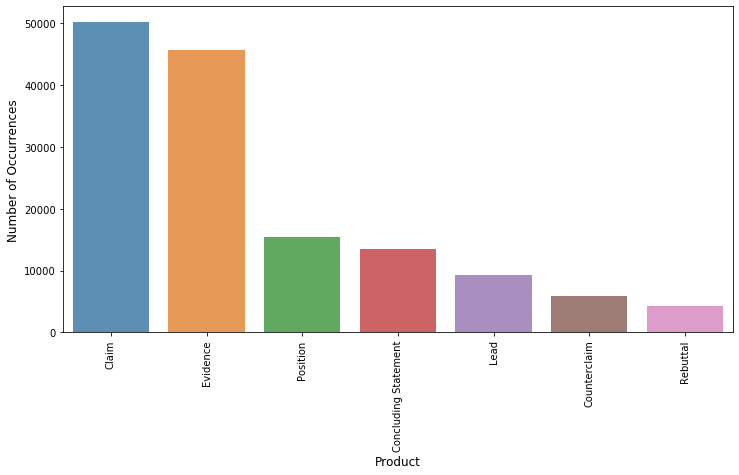

In [82]:
plt.figure(figsize=(12,6))
sns.barplot(train_df.discourse_type.value_counts().index, train_df.discourse_type.value_counts().values ,alpha=0.8)
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Product', fontsize=12)
plt.xticks(rotation=90)
plt.show()

In [77]:
import seaborn as sns

C:\Users\user\Anaconda3\lib\site-packages\seaborn\_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


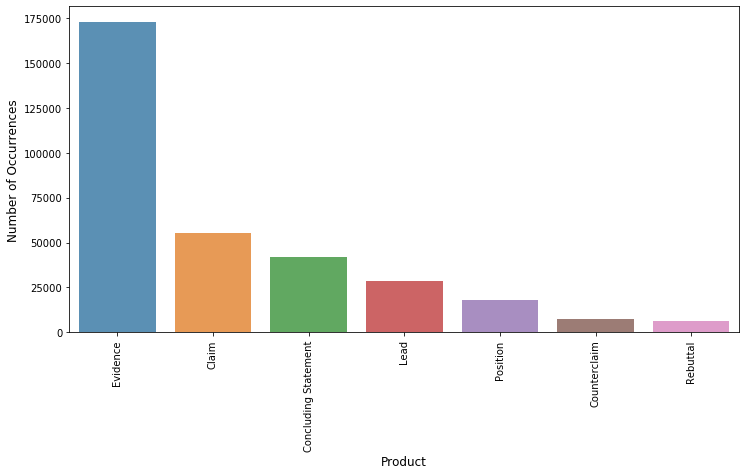

In [83]:
plt.figure(figsize=(12,6))
sns.barplot(copy_train_df.discourse_type.value_counts().index, copy_train_df.discourse_type.value_counts().values ,alpha=0.8)
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Product', fontsize=12)
plt.xticks(rotation=90)
plt.show()